# 1. 본실험 노트북 (Whisper large-v3)

숫자 CAPTCHA 생성 → 잡음 혼합 → 공격자(음성인식 모델)의 해독 → 객관적 명료도(STOI·ESTOI) 계산 → 분석의 순서로 진행합니다. 논문의 표 3~6과 그림 1은 6번 셀들에서 만들어집니다.

## 결과만 다시 만들기 (GPU 불필요)
저장소에 본실험 결과 CSV(`runs/main/`)가 들어 있습니다. **0번 셀과 6번 셀들만** 실행하면 표와 그림 1을 다시 만들 수 있습니다.

## 처음부터 다시 실행하기
1. **시험 실행:** 0번 셀을 `DRY_RUN = True`로 바꾸고 맨 위부터 끝까지 실행합니다(조건당 5개, 약 20~30분). 4번 셀 앞에서 `02_main_separation` 노트북도 한 번 실행합니다. 결과는 `runs/dryrun/`에 저장됩니다.
2. **본실험 1일차:** `DRY_RUN = False`로 두고 **Run All**을 누릅니다. 3-3(약 7시간) → 4는 분리 결과가 없어 자동으로 건너뜀 → 5 명료도(약 1시간) → 6 분석까지 자동으로 진행됩니다.
3. **본실험 2일차:** 이 노트북의 커널을 끄고 → `02_main_separation` 노트북 실행(약 30분) → 그 커널을 끄고 → 이 노트북에서 **0 → 3-1 → 3-2 → 4 → 6** 순서로 실행합니다(4번 셀만 약 5시간).

## 중간에 끊겼을 때
커널 재시작 → **0, 3-1, 3-2** 셀 실행 → 멈춘 셀(3-3, 4, 5)을 다시 실행하면 끝난 것은 건너뛰고 이어서 진행합니다.

## 주의
- Windows + NVIDIA GPU(8GB)에서 실행하였습니다. 노트북 PC는 전원을 연결하고 절전 모드를 끄세요.
- WAV 파일을 만들기 때문에 디스크 여유 공간이 약 10GB 필요합니다(WAV는 저장소에 올리지 않습니다).
- 코드의 공격자 이름 `base`·`hintX`·`hintO`·`sep_base`·`sep_hintX`는 논문의 A1~A5에 대응합니다(README 참고).

In [ ]:
# ===== 0. 설정 =====
import json
from pathlib import Path
import numpy as np
import pandas as pd
import soundfile as sf
from tqdm import tqdm

ROOT = Path.cwd()

DRY_RUN = False # True: 시험 실행(조건당 5개) / False: 본실험(조건당 200개)

N_CAPTCHA = 5 if DRY_RUN else 200
RUN = ROOT / "runs" / ("dryrun" if DRY_RUN else "main")

FS, SEED = 16000, 42
N_DIGITS = 6
VOICES = ["en-US-GuyNeural", "en-US-ChristopherNeural", "en-GB-RyanNeural",
          "en-US-JennyNeural", "en-US-AriaNeural", "en-GB-SoniaNeural"]
SNRS = [-25, -20, -15, -10, -5, 0, 5, 10, 15, 20]
ADAPT_SNRS = [-20, -15, -10, -5, 0, 5] # 적응형 공격자(A2~A5)를 적용할 SNR
# 잡음 이름 → 논문 용어
# white: 백색 잡음, ssn: 어음스펙트럼 잡음 (정상 잡음)
# band_low/mid/high: 대역 제한 잡음 (저역, 중역, 고역)
# talk1/2/4: 경쟁 화자 1·2·4명, babble8: 다화자 잡음(8명)
NOISE_LIST = ["white", "band_low", "band_mid", "band_high", "ssn",
              "babble8", "talk1", "talk2", "talk4"]
SEP_NOISES = ["talk1", "talk2", "talk4", "babble8"] # 음성 분리 공격자(A4, A5)를 적용할 잡음
TALK_MIN_SNR = -20 # 경쟁 화자 1, 2, 4명 조건은 -25dB 제외 (클리핑 방지)
GAIN = 0.2 # 출력 이득 고정 (제시 음량)

BANK = ROOT / "data/digits/normal" # 숫자 음성 60개 (00_digit_bank 노트북)
MUSAN_SPEECH = ROOT / "data/noise/musan/speech" # MUSAN 말소리 (README의 '데이터 준비' 참고)
CLEAN, MIXED = RUN / "clean", RUN / "mixed"
SEPARATED, RES = RUN / "separated", RUN / "results"
for d in [CLEAN, MIXED, SEPARATED, RES]:
    d.mkdir(parents=True, exist_ok=True)

# 음성 분리 노트북(02_main_separation)이 같은 설정을 읽도록 저장
(ROOT / "runs").mkdir(exist_ok=True)
(ROOT / "runs" / "active_run.json").write_text(json.dumps({
    "ROOT": str(ROOT), "RUN": str(RUN), "SEP_NOISES": SEP_NOISES, "ADAPT_SNRS": ADAPT_SNRS
}, ensure_ascii=False, indent=2), encoding="utf-8")

def append_rows(path, rows):
    """결과를 CSV에 덧붙여 저장"""
    if rows:
        pd.DataFrame(rows).to_csv(path, mode="a", header=not path.exists(), index=False)

def done_keys(path):
    """이미 처리한 항목의 key 목록"""
    return set(pd.read_csv(path, usecols=["key"])["key"]) if path.exists() else set()

print("실행 모드:", "시험(조건당 5개)" if DRY_RUN else "본실험(조건당 200개)")
print("저장 위치:", RUN.relative_to(ROOT).as_posix())

실행 모드: 본실험(조건당 200개)
저장 위치: runs/main


## 1. 깨끗한 CAPTCHA
숫자 음성(`data/digits/normal`)을 그대로 쓰므로 인터넷이 필요 없습니다. 시드가 같으므로 앞부분은 예비 실험과 똑같이 만들어집니다.

In [ ]:
# ===== 1. 깨끗한 CAPTCHA 만들기 (숫자 음성 재사용, 인터넷 불필요, 1분 이내) =====
missing = [f"{v}_{d}.wav" for v in VOICES for d in range(10) if not (BANK / f"{v}_{d}.wav").exists()]
assert not missing, f"숫자 음성 폴더에 없는 파일: {missing[:5]} (00_digit_bank 노트북을 먼저 실행)"

rng = np.random.default_rng(SEED)
rows = []
for i in range(N_CAPTCHA):
    voice = VOICES[i % len(VOICES)]
    digits = rng.integers(0, 10, N_DIGITS)
    parts = [np.zeros(int(0.5 * FS))]
    for j, d in enumerate(digits):
        clip, _ = sf.read(BANK / f"{voice}_{d}.wav")
        parts.append(clip)
        if j < N_DIGITS - 1:
            parts.append(np.zeros(int(rng.uniform(0.3, 0.6) * FS)))
    parts.append(np.zeros(int(0.5 * FS)))
    audio = np.concatenate(parts)
    clip_id = f"cap_{i:04d}"
    path = CLEAN / f"{clip_id}.wav"
    sf.write(path, audio, FS)
    rows.append({"clip_id": clip_id, "answer": "".join(map(str, digits)), "voice": voice,
                 "duration": round(len(audio) / FS, 2), "path": path.relative_to(ROOT).as_posix()})

clean_df = pd.DataFrame(rows)
clean_df.to_csv(RUN / "clean.csv", index=False)

# 예비 실험과 같은 방식으로 만들어졌는지 확인 (예비 실험의 clean.csv가 있을 때만)
pilot_csv = ROOT / "pilot/data/clean.csv"
if pilot_csv.exists():
    pilot = pd.read_csv(pilot_csv, dtype={"answer": str})
    k = min(len(pilot), len(clean_df))
    same = (pilot.answer.head(k).values == clean_df.answer.head(k).values).all()
    print(len(clean_df), "개 생성 | 예비 실험과 앞", k, "개 정답 일치:", same)
else:
    print(len(clean_df), "개 생성")

200 개 생성 | 예비 실험과 앞 50 개 정답 일치: True


## 2. 잡음 섞기
시드가 고정되어 있어 다시 실행해도 같은 파일이 만들어집니다. 이미 끝났다면 2-2는 다시 실행할 필요가 없습니다.

In [ ]:
# ===== 2-1. 잡음 함수 =====
from scipy.signal import butter, sosfilt, welch

def white_noise(n, rng):
    return rng.standard_normal(n)

def band_noise(n, rng, lo, hi):
    """대역 제한 잡음: 백색 잡음에 6차 Butterworth 대역 통과 필터"""
    sos = butter(6, [lo, hi], btype="band", fs=FS, output="sos")
    x = sosfilt(sos, rng.standard_normal(n + FS // 10))
    return x[FS // 10:]                                # 필터 시작 부분 0.1초는 버림

# 어음스펙트럼 잡음(SSN): 숫자 음성 전체의 장기 평균 스펙트럼(Welch)으로 백색 잡음을 성형
bank_audio = np.concatenate([sf.read(p)[0] for p in sorted(BANK.glob("*.wav"))])
f_ltas, psd_ltas = welch(bank_audio, fs=FS, nperseg=1024)

def ssn_noise(n, rng):
    spec = np.fft.rfft(rng.standard_normal(n))
    shape = np.sqrt(np.interp(np.fft.rfftfreq(n, 1 / FS), f_ltas, psd_ltas))
    return np.fft.irfft(spec * shape, n)

speech_files = sorted(MUSAN_SPEECH.rglob("*.wav"))
assert speech_files, "MUSAN 말소리 파일을 찾지 못했습니다 (README의 '데이터 준비' 참고)"

def one_talker(n, rng):
    """MUSAN 말소리에서 무작위 구간 하나를 뽑아 RMS를 1로 맞춤"""
    for _ in range(50):
        path = speech_files[rng.integers(len(speech_files))]
        info = sf.info(path)
        if info.frames <= n:
            continue
        start = rng.integers(0, info.frames - n)
        x, _ = sf.read(path, start=start, stop=start + n)
        if x.ndim > 1:
            x = x.mean(axis=1)
        rms = np.sqrt(np.mean(x ** 2))
        if rms > 1e-3:
            return x / rms
    raise RuntimeError("말소리 구간을 찾지 못했습니다")

def babble_noise(n, rng, k):
    """경쟁 화자 k명을 같은 크기로 합산 (k=8이면 다화자 잡음)"""
    return sum(one_talker(n, rng) for _ in range(k))

NOISES = {
    "white":     lambda n, rng: white_noise(n, rng),          # 백색 잡음
    "band_low":  lambda n, rng: band_noise(n, rng, 100, 1000),  # 대역 제한 잡음: 저역
    "band_mid":  lambda n, rng: band_noise(n, rng, 1000, 4000), # 대역 제한 잡음: 중역
    "band_high": lambda n, rng: band_noise(n, rng, 4000, 7900), # 대역 제한 잡음: 고역
    "ssn":       ssn_noise,                                     # 어음스펙트럼 잡음
    "babble8":   lambda n, rng: babble_noise(n, rng, 8),        # 다화자 잡음(8명)
    "talk1":     lambda n, rng: babble_noise(n, rng, 1),        # 경쟁 화자 1명
    "talk2":     lambda n, rng: babble_noise(n, rng, 2),        # 경쟁 화자 2명
    "talk4":     lambda n, rng: babble_noise(n, rng, 4),        # 경쟁 화자 4명
}

def mix_at_snr(speech, noise, snr_db):
    """CAPTCHA 전체 구간(앞뒤 무음 포함)의 전력 비로 SNR을 맞춰 섞음"""
    p_s, p_n = np.mean(speech ** 2), np.mean(noise ** 2)
    return speech + noise * np.sqrt(p_s / (p_n * 10 ** (snr_db / 10)))

print("잡음 함수 준비 완료:", list(NOISES), "| MUSAN 말소리", len(speech_files), "개")

잡음 함수 준비 완료: ['white', 'band_low', 'band_mid', 'band_high', 'ssn', 'babble8', 'talk1', 'talk2', 'talk4'] | MUSAN 말소리 426 개


In [ ]:
# ===== 2-2. 잡음 섞기 (본실험 약 10~20분) =====
rng = np.random.default_rng(SEED)
rows = []
for noise_name in NOISE_LIST:
    for r in tqdm(clean_df.itertuples(), total=len(clean_df), desc=noise_name):
        speech, _ = sf.read(ROOT / r.path)
        noise = NOISES[noise_name](len(speech), rng)        # 잡음은 CAPTCHA마다 한 번만 만듦
        for snr in SNRS:
            if noise_name.startswith("talk") and snr < TALK_MIN_SNR:
                continue
            mixed = mix_at_snr(speech, noise, snr) * GAIN
            folder = MIXED / noise_name / f"snr{snr}"
            folder.mkdir(parents=True, exist_ok=True)
            path = folder / f"{r.clip_id}.wav"
            sf.write(path, mixed, FS)
            rows.append({"key": f"{noise_name}|{snr}|{r.clip_id}", "clip_id": r.clip_id,
                         "answer": r.answer, "voice": r.voice, "noise": noise_name, "snr": snr,
                         "peak": round(float(np.abs(mixed).max()), 3),
                         "path": path.relative_to(ROOT).as_posix()})

mix_df = pd.DataFrame(rows)
mix_df.to_csv(RUN / "mixed.csv", index=False)
n_clip = int((mix_df.peak >= 0.999).sum())          # 진폭이 1을 넘어 잘린(클리핑) 파일
print(len(mix_df), "개 생성 | 클리핑된(peak≥1) 파일:", n_clip, "개")
if n_clip:
    print(mix_df[mix_df.peak >= 0.999].groupby(["noise", "snr"]).size())

talk4: 100%|█████████████████████████████████████████████████████████████████████████| 200/200 [00:06<00:00, 32.23it/s]

17400 개 생성 | 클리핑된(peak≥1) 파일: 28 개
noise    snr
babble8  -25     9
talk1    -20    13
         -15     1
talk2    -20     5
dtype: int64


## 3. 공격자(Whisper)의 해독
| 코드 이름 | 논문 | 설정 |
|---|---|---|
| `base` | A1 기본 | 온도 0, 재시도 없음, 비음성 판정 기본값 |
| `hintX` | A2 디코딩 조정 | 온도 폴백(0~1.0), 비음성 판정 끔 |
| `hintO` | A3 디코딩 조정 + 프롬프트 | A2 + 'six random digits'를 알려 주는 초기 프롬프트 |

In [ ]:
# ===== 3-1. Whisper 준비 (GPU) =====
import os, sys, ctypes, re

if os.name == "nt":   # Windows: pip로 설치한 cuBLAS DLL을 직접 불러옴 (Linux·macOS에서는 필요 없음)
    os.environ["CUDA_CACHE_MAXSIZE"] = "4294967296"
    cublas_bin = Path(sys.prefix) / "Lib/site-packages/nvidia/cublas/bin"
    os.environ["PATH"] = str(cublas_bin) + os.pathsep + os.environ["PATH"]
    ctypes.CDLL(str(cublas_bin / "cublasLt64_12.dll"))
    ctypes.CDLL(str(cublas_bin / "cublas64_12.dll"))

import ctranslate2
from faster_whisper import WhisperModel
if "model" not in globals():
    model = WhisperModel("large-v3", device="cuda", compute_type="float16")

PROMPT = "The speaker reads six random digits, for example: 4 0 7 2 9 1."
FALLBACK = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]      # 온도 폴백(temperature fallback)

def transcribe_base(path):          # A1 기본: 온도 0, 재시도 없음, 비음성 판정 기본값
    segs, _ = model.transcribe(str(path), language="en", beam_size=5, temperature=0.0)
    return "".join(s.text for s in segs).strip()

def transcribe_hintO(path):         # A3 디코딩 조정 + 프롬프트: A2 + 'six random digits'를 알려 주는 초기 프롬프트
    segs, _ = model.transcribe(str(path), language="en", beam_size=5, temperature=FALLBACK,
                               no_speech_threshold=None, initial_prompt=PROMPT)
    return "".join(s.text for s in segs).strip()

def transcribe_hintX(path):         # A2 디코딩 조정: 온도 폴백 + 비음성 판정 끔
    segs, _ = model.transcribe(str(path), language="en", beam_size=5, temperature=FALLBACK,
                               no_speech_threshold=None)
    return "".join(s.text for s in segs).strip()

# 코드 이름 → 논문: base=A1, hintX=A2, hintO=A3 (음성 분리 결합: sep_base=A4, sep_hintX=A5)
ATTACKERS = {"base": transcribe_base, "hintO": transcribe_hintO, "hintX": transcribe_hintX}

In [ ]:
# ===== 3-2. 채점 함수와 '이어하기' 실행기 =====
WORDS = {"zero": "0", "one": "1", "two": "2", "three": "3", "four": "4",
         "five": "5", "six": "6", "seven": "7", "eight": "8", "nine": "9"}

def to_digits(text):
    """출력에서 숫자와 숫자 단어(zero~nine)만 골라 숫자열로 바꿈"""
    out = []
    for t in re.findall(r"[a-z]+|\d", str(text).lower()):
        if t.isdigit():
            out.append(t)
        elif t in WORDS:
            out.append(WORDS[t])
    return "".join(out)

def cer(hyp, ref):
    """문자 오류율 (편집 거리 ÷ 정답 길이)"""
    d = list(range(len(hyp) + 1))
    for i, r in enumerate(ref, 1):
        prev, d[0] = d[0], i
        for j, h in enumerate(hyp, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, prev + (r != h))
    return d[len(hyp)] / len(ref)

def run_asr(name, fn, jobs, batch=50):
    """jobs를 풀어서 RES/asr_{name}.csv에 조금씩 저장. 끊겨도 다시 실행하면 이어서 진행."""
    out = RES / f"asr_{name}.csv"
    done = done_keys(out)
    todo = [j for j in jobs if j["key"] not in done]
    print(f"[{name}] 전체 {len(jobs)} | 완료 {len(jobs) - len(todo)} | 남음 {len(todo)}")
    ctranslate2.set_random_seed(SEED)
    buf = []
    for job in tqdm(todo, desc=name, mininterval=10):   # 출력 갱신 간격 (IOPub 경고 방지)
        raw = fn(ROOT / job["path"])
        hyp, ans = to_digits(raw), job["answer"]
        buf.append({**job, "attacker": name, "raw": raw, "hyp": hyp,
                    "exact": hyp == ans,                    # 완전 일치 채점
                    "first6": hyp[:len(ans)] == ans,        # 앞 6자리 일치 = 공격 성공 (주 지표)
                    "contains": ans in hyp, "cer6": round(cer(hyp[:len(ans)], ans), 3),
                    "n_digits": len(hyp)})
        if len(buf) >= batch:
            append_rows(out, buf)
            buf = []
    append_rows(out, buf)

clean_df = pd.read_csv(RUN / "clean.csv", dtype={"answer": str})
mix_df = pd.read_csv(RUN / "mixed.csv", dtype={"answer": str})
clean_jobs = [{"key": f"none|clean|{r.clip_id}", "clip_id": r.clip_id, "answer": r.answer,
               "noise": "none", "snr": None, "path": r.path} for r in clean_df.itertuples()]
mix_jobs = mix_df[["key", "clip_id", "answer", "noise", "snr", "path"]].to_dict("records")
adapt_jobs = [j for j in mix_jobs if j["snr"] in ADAPT_SNRS]
print(f"작업 수: 기본 {len(clean_jobs) + len(mix_jobs)} | 적응형(설정마다) {len(adapt_jobs)}")

작업 수: 기본 17600 | 적응형(설정마다) 10800


In [ ]:
# ===== 3-3. 밤새 돌리는 셀: A1 기본 → A2 디코딩 조정 → A3 디코딩 조정 + 프롬프트 (본실험 약 7시간) =====
# 중간에 멈추거나 컴퓨터가 꺼져도, 위의 '준비' 셀들을 다시 실행한 뒤 이 셀을 다시 실행하면 이어서 진행합니다.
run_asr("base",  ATTACKERS["base"],  clean_jobs + mix_jobs)   # A1
run_asr("hintX", ATTACKERS["hintX"], adapt_jobs)              # A2
run_asr("hintO", ATTACKERS["hintO"], adapt_jobs)              # A3
print("모든 공격자 완료")

[base] 전체 17600 | 완료 50 | 남음 17550


## 4. 음성 분리 공격자 (A4·A5)
**이 셀을 실행하기 전에** `02_main_separation` 노트북을 실행해 `separated.csv`를 만들어야 합니다. 그래픽카드 메모리 때문에 두 노트북을 동시에 GPU로 돌리지 마세요(한쪽 커널을 끈 뒤 실행).

In [ ]:
# ===== 4. 분리된 두 출력 받아 적기 (02_main_separation 노트북을 먼저 실행, 본실험 약 5시간) =====
def pick(h0, h1, n=N_DIGITS):
    """두 출력 중 숫자 개수가 6개에 가장 가까운 쪽을 공격자의 답으로 고름"""
    return h0 if abs(len(h0) - n) <= abs(len(h1) - n) else h1

def run_sep(name, fn, batch=50):
    sep_df = pd.read_csv(RUN / "separated.csv", dtype={"answer": str})
    out = RES / f"asr_{name}.csv"
    done = done_keys(out)
    todo = sep_df[~sep_df.key.isin(done)]
    print(f"[{name}] 전체 {len(sep_df)} | 완료 {len(sep_df) - len(todo)} | 남음 {len(todo)}")
    ctranslate2.set_random_seed(SEED)
    buf = []
    for r in tqdm(todo.itertuples(), total=len(todo), desc=name, mininterval=10):
        raw0, raw1 = fn(ROOT / r.path_s0), fn(ROOT / r.path_s1)
        h0, h1 = to_digits(raw0), to_digits(raw1)
        hyp = pick(h0, h1)
        buf.append({"key": r.key, "clip_id": r.clip_id, "answer": r.answer, "noise": r.noise,
                    "snr": r.snr, "attacker": name, "raw_s0": raw0, "raw_s1": raw1, "hyp": hyp,
                    "first6": hyp[:N_DIGITS] == r.answer,                                     # 공격자가 실제로 고른 답
                    "either": h0[:N_DIGITS] == r.answer or h1[:N_DIGITS] == r.answer})    # 둘 중 하나라도 맞음 (상한)
        if len(buf) >= batch:
            append_rows(out, buf)
            buf = []
    append_rows(out, buf)

if (RUN / "separated.csv").exists():
    run_sep("sep_base", transcribe_base)     # A4 분리
    run_sep("sep_hintX", transcribe_hintX)   # A5 분리 + 디코딩 조정
    print("음성 분리 공격자 완료")
else:
    print("separated.csv가 아직 없음 → 건너뜀 (02_main_separation 노트북 실행 후 이 셀을 다시 실행)")

[sep_base] 전체 4800 | 완료 0 | 남음 4800


sep_base: 100%|██████████████████████████████████████████████████████████████████| 4800/4800 [1:56:48<00:00,  1.46s/it]


[sep_hintX] 전체 4800 | 완료 0 | 남음 4800


sep_hintX: 100%|█████████████████████████████████████████████████████████████████| 4800/4800 [3:01:33<00:00,  2.27s/it]

음성 분리 공격자 완료


## 5. 객관적 명료도 (STOI·ESTOI)
GPU를 쓰지 않으며, 이어하기가 됩니다. 이 셀만 단독으로 돌릴 때는 0번 셀만 먼저 실행하면 됩니다.

In [ ]:
# ===== 5. 객관적 명료도 (STOI·ESTOI, CPU, 본실험 약 1시간, 이어하기 가능) =====
from pystoi import stoi

mix_df = pd.read_csv(RUN / "mixed.csv", dtype={"answer": str})
out = RES / "intelligibility.csv"
done = done_keys(out)
todo = mix_df[~mix_df.key.isin(done)]
print(f"[명료도] 전체 {len(mix_df)} | 완료 {len(mix_df) - len(todo)} | 남음 {len(todo)}")
buf = []
for r in tqdm(todo.itertuples(), total=len(todo), desc="STOI", mininterval=10):
    clean, fs = sf.read(CLEAN / f"{r.clip_id}.wav")      # 기준: 잡음을 섞기 전 음성
    mixed, _ = sf.read(ROOT / r.path)
    buf.append({"key": r.key, "clip_id": r.clip_id, "noise": r.noise, "snr": r.snr,
                "stoi": stoi(clean, mixed, fs, extended=False),
                "estoi": stoi(clean, mixed, fs, extended=True)})
    if len(buf) >= 200:
        append_rows(out, buf)
        buf = []
append_rows(out, buf)
print("명료도 완료")

[명료도] 전체 17400 | 완료 17400 | 남음 0


STOI: 0it [00:00, ?it/s]

명료도 완료


## 6. 분석: 논문의 표와 그림
0번 셀만 실행된 상태에서도 돌아갑니다(모든 결과를 CSV에서 다시 읽음). 결과는 `runs/main/results/`에 저장됩니다.

| 셀 | 논문 | 저장 파일 |
|---|---|---|
| 6-1 | 표 3, 3.7절 깨끗한 음성 결과 | `summary_final.csv`, `table3_best_attacker_rate.csv`, `table_rate_by_attacker.csv` |
| 6-2 | 그림 1 (설계 공간 지도) | `fig_final.png` |
| 6-3 | 표 4, RQ2 | `table4_separation_effect.csv` |
| 6-4 | 표 5 | `table_rq3_estoi_threshold.csv` |
| 6-5 | 표 6 | `table_failure_types.csv`, `table6_failure_types_pct.csv` |
| 6-6 | 3.4절 클리핑 점검 | (출력만) |

In [ ]:
# ===== 6-1. 요약표: 조건마다 가장 강한 공격자 + 95% 신뢰구간 (표 3) =====
LABEL = {"base": "A1 기본", "hintX": "A2 디코딩 조정", "hintO": "A3 디코딩 조정 + 프롬프트",
         "sep_base": "A4 분리", "sep_hintX": "A5 분리 + 디코딩 조정"}
NOISE_LABEL = {"white": "백색 잡음", "ssn": "어음스펙트럼 잡음", "babble8": "다화자 잡음(8명)",
               "band_low": "저역", "band_mid": "중역", "band_high": "고역",
               "talk1": "경쟁 화자 1명", "talk2": "경쟁 화자 2명", "talk4": "경쟁 화자 4명"}
NOISE_ORDER = list(NOISE_LABEL)          # 논문 표 3의 열 순서

def wilson(k, n, z=1.96):
    """공격 성공률의 95% 신뢰구간 (Wilson 방법)"""
    k, n = np.asarray(k, dtype=float), np.asarray(n, dtype=float)
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return np.clip(c - h, 0, 1), np.clip(c + h, 0, 1)

print("결과 폴더:", RES.relative_to(ROOT).as_posix())
frames = []
for name in LABEL:
    p = RES / f"asr_{name}.csv"
    if p.exists():
        df_ = pd.read_csv(p, dtype={"answer": str, "hyp": str},
                          usecols=["key", "clip_id", "noise", "snr", "attacker", "first6"])
        frames.append(df_)
        print(f"  읽음: asr_{name}.csv ({len(df_)}행) = {LABEL[name]}")
    else:
        print(f"  없음: asr_{name}.csv")
allatt = pd.concat(frames, ignore_index=True)
allatt["snr"] = allatt["snr"].astype(float)

cl = allatt[allatt.noise == "none"]
lo, hi = wilson(cl.first6.sum(), len(cl))
print(f"깨끗한 음성 공격 성공률 (A1): {cl.first6.mean():.3f} (95% CI {lo:.3f}~{hi:.3f}, n={len(cl)})")

g = (allatt[allatt.noise != "none"].groupby(["noise", "snr", "attacker"])["first6"]
     .agg(k="sum", n="count").reset_index())
g["rate"] = g.k / g.n
g.pivot_table(index=["noise", "snr"], columns="attacker", values="rate") \
 .rename(columns=LABEL).to_csv(RES / "table_rate_by_attacker.csv", encoding="utf-8-sig")

best = g.loc[g.groupby(["noise", "snr"])["rate"].idxmax()].copy()      # 가장 강한 공격자
best["lo"], best["hi"] = wilson(best.k, best.n)
met = pd.read_csv(RES / "intelligibility.csv")
met["snr"] = met["snr"].astype(float)
est = met.groupby(["noise", "snr"])[["stoi", "estoi"]].mean().reset_index()
final = best.merge(est, on=["noise", "snr"])
final["best_attacker"] = final.attacker.map(LABEL)
final.to_csv(RES / "summary_final.csv", index=False, encoding="utf-8-sig")

# 확인용: 경쟁 화자 1명 -10dB에서 공격자별 공격 성공률과 가장 강한 공격자
print("\n[확인] 경쟁 화자 1명, -10dB 공격자별 공격 성공률")
print(g[(g.noise == "talk1") & (g.snr == -10)].assign(attacker=lambda d: d.attacker.map(LABEL))
      [["attacker", "rate"]].to_string(index=False))
t = final[(final.noise == "talk1") & (final.snr == -10)].iloc[0]
print(f"→ 가장 강한 공격자: {t.rate:.3f} ({t.best_attacker})\n")

# 표 3: 가장 강한 공격자의 공격 성공률 (%)
table3 = (final.pivot(index="snr", columns="noise", values="rate")[NOISE_ORDER]
          .rename(columns=NOISE_LABEL) * 100).round(1)
table3.index = table3.index.astype(int).rename("SNR(dB)")
table3.to_csv(RES / "table3_best_attacker_rate.csv", encoding="utf-8-sig")
table3

결과 폴더: runs/main/results
  읽음: asr_base.csv (17600행) = A1 기본
  읽음: asr_hintX.csv (10800행) = A2 디코딩 조정
  읽음: asr_hintO.csv (10800행) = A3 디코딩 조정 + 프롬프트
  읽음: asr_sep_base.csv (4800행) = A4 분리
  읽음: asr_sep_hintX.csv (4800행) = A5 분리 + 디코딩 조정
깨끗한 음성 공격 성공률 (A1): 1.000 (95% CI 0.981~1.000, n=200)

[확인] 경쟁 화자 1명, -10dB 공격자별 공격 성공률
      attacker  rate
         A1 기본 0.075
A3 디코딩 조정 + 프롬프트 0.095
     A2 디코딩 조정 0.075
      A4 분리 0.870
  A5 분리 + 디코딩 조정 0.870
→ 가장 강한 공격자: 0.870 (A4 분리)



noise,백색 잡음,어음스펙트럼 잡음,다화자 잡음(8명),저역,중역,고역,경쟁 화자 1명,경쟁 화자 2명,경쟁 화자 4명
SNR(dB),,,,,,,,,
-25,0.0,0.0,0.0,87.0,90.5,98.0,NaN,NaN,NaN
-20,0.0,0.0,0.0,92.0,93.0,98.0,39.0,0.5,0.0
-15,28.0,5.0,0.0,95.0,95.0,98.0,69.0,4.5,1.5
-10,63.0,55.0,7.5,98.0,97.5,97.5,87.0,14.5,11.5
-5,91.0,92.5,63.5,98.5,98.0,99.0,91.5,44.0,45.5
0,98.5,99.0,94.0,98.5,98.0,99.5,96.0,82.5,93.0
5,99.5,99.5,97.5,99.0,98.5,99.5,97.0,99.0,97.0
10,100.0,99.5,97.0,99.0,98.5,100.0,98.0,99.0,98.0
15,100.0,99.5,97.0,100.0,99.0,100.0,99.0,99.0,99.0


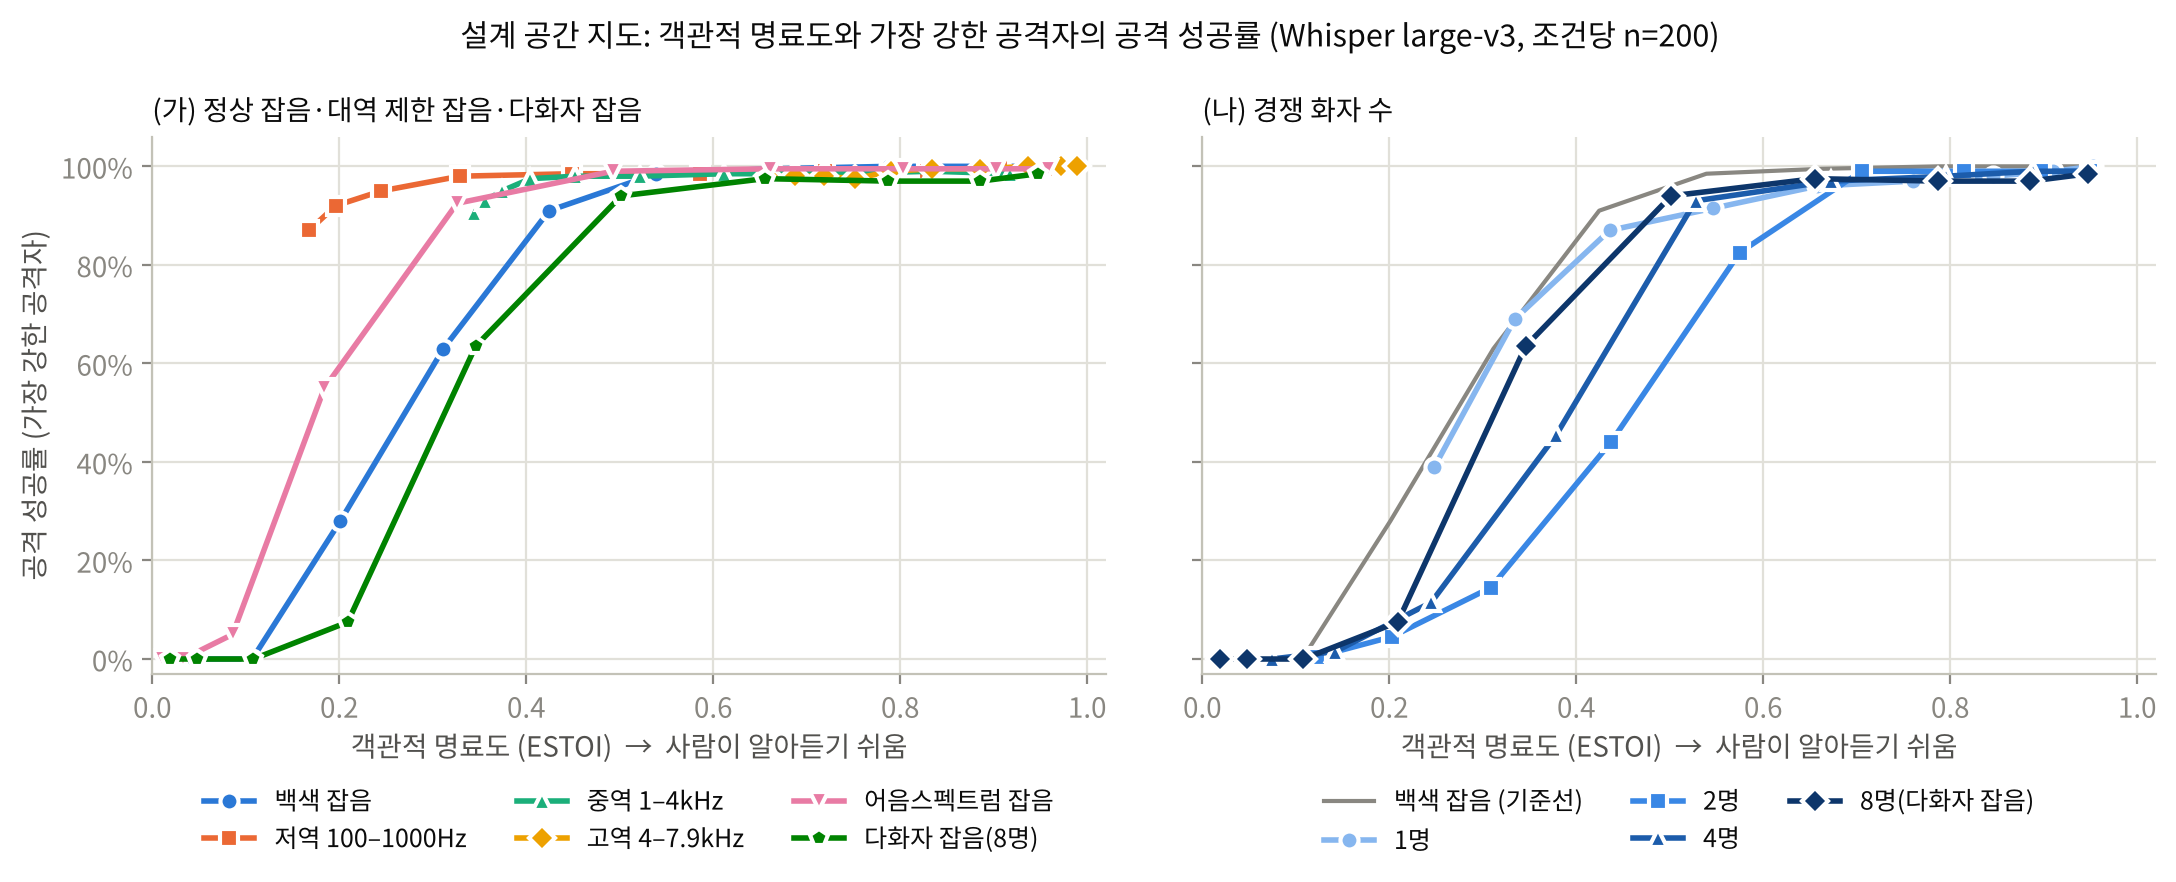

In [ ]:
# ===== 6-2. 그림 1: 설계 공간 지도 =====
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import PercentFormatter

# 한글 글꼴: 설치된 것 중 먼저 찾은 것을 사용 (Windows: 맑은 고딕, macOS: AppleGothic, Linux: Noto Sans CJK KR)
_installed = {f.name for f in font_manager.fontManager.ttflist}
for _font in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP"]:
    if _font in _installed:
        plt.rcParams["font.family"] = _font
        break
plt.rcParams["axes.unicode_minus"] = False
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"

STYLE = {   # (가) 정상 잡음·대역 제한 잡음·다화자 잡음: 순서 고정, 색과 모양은 잡음을 따라감 (색맹 검사 통과)
    "white":     ("백색 잡음",         "#2a78d6", "o"),
    "band_low":  ("저역 100–1000Hz",   "#eb6834", "s"),
    "band_mid":  ("중역 1–4kHz",       "#1baf7a", "^"),
    "band_high": ("고역 4–7.9kHz",     "#eda100", "D"),
    "ssn":       ("어음스펙트럼 잡음",  "#e87ba4", "v"),
    "babble8":   ("다화자 잡음(8명)",   "#008300", "p"),
}
TALK = {    # (나) 경쟁 화자 수: 순서가 있으므로 같은 색의 진하기
    "talk1":   ("1명",              "#86b6ef", "o"),
    "talk2":   ("2명",              "#3987e5", "s"),
    "talk4":   ("4명",              "#1c5cab", "^"),
    "babble8": ("8명(다화자 잡음)",  "#0d366b", "D"),
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
panels = [(axes[0], STYLE, "(가) 정상 잡음·대역 제한 잡음·다화자 잡음", None),
          (axes[1], TALK, "(나) 경쟁 화자 수", "white")]
for ax, style, title, ref in panels:
    if ref:
        w = final[final.noise == ref].sort_values("estoi")
        ax.plot(w.estoi, w.rate, color=MUTED, lw=1.5, label="백색 잡음 (기준선)")
    for noise, (label, color, marker) in style.items():
        s = final[final.noise == noise].sort_values("estoi")
        if s.empty:
            continue
        ax.plot(s.estoi, s.rate, color=color, lw=2, marker=marker, ms=6.5,
                mec="white", mew=1.5, label=label)
    ax.set_title(title, color=INK, fontsize=10, loc="left")
    ax.set_xlim(0, 1.02)
    ax.set_xlabel("객관적 명료도 (ESTOI)  →  사람이 알아듣기 쉬움", color=INK2)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=MUTED)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3,
              frameon=False, labelcolor=INK, fontsize=9)

axes[0].set_ylim(-0.03, 1.06)
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].set_ylabel("공격 성공률 (가장 강한 공격자)", color=INK2)
fig.suptitle(f"설계 공간 지도: 객관적 명료도와 가장 강한 공격자의 공격 성공률 (Whisper large-v3, 조건당 n={N_CAPTCHA})",
             color=INK, fontsize=11)
fig.tight_layout()
fig.savefig(RES / "fig_final.png", dpi=200, facecolor="white", bbox_inches="tight")
plt.show()

In [ ]:
# ===== 6-3. 표 4: 적응형 공격의 효과 (RQ2) =====
# 분리 전 = A1~A3 중 가장 높은 공격 성공률, 분리 후 = A1~A5 중 가장 높은 값(가장 강한 공격자)
rate = g.pivot_table(index=["noise", "snr"], columns="attacker", values="rate")
before = rate[["base", "hintX", "hintO"]].max(axis=1)
after = rate.max(axis=1)

t4 = pd.DataFrame({"before": before, "after": after}).loc[SEP_NOISES]
t4 = t4[t4.index.get_level_values("snr").isin([-15, -10, -5, 0])] * 100
table4 = (t4.apply(lambda r: f"{r['before']:.1f} → {r['after']:.1f}", axis=1)
            .unstack("snr").reindex(SEP_NOISES))
table4.index = [NOISE_LABEL[n] for n in table4.index]
table4.columns = [f"{int(s)}dB" for s in table4.columns]
table4.to_csv(RES / "table4_separation_effect.csv", encoding="utf-8-sig")

# 기본 공격자(A1)만으로 평가했을 때와 가장 강한 공격자의 차이
a1, top = rate.loc[("talk1", -10.0), "base"], after.loc[("talk1", -10.0)]
print(f"경쟁 화자 1명 -10dB: A1 {a1*100:.1f}% → 가장 강한 공격자 {top*100:.1f}% (차이 {(top-a1)*100:.1f}%p)")
print(f"경쟁 화자 1명 0dB·5dB, 분리 전: {before.loc[('talk1', 0.0)]*100:.1f}%, {before.loc[('talk1', 5.0)]*100:.1f}%")
low = after.loc[["talk2", "talk4", "babble8"]]
print(f"경쟁 화자 2명 이상·다화자 잡음, -10dB 이하의 최댓값: {low[low.index.get_level_values('snr') <= -10].max()*100:.1f}%")
print("\n표 4. 음성 분리 공격자(A4·A5) 포함 전 → 후 공격 성공률 (%)")
table4

경쟁 화자 1명 -10dB: A1 7.5% → 가장 강한 공격자 87.0% (차이 79.5%p)
경쟁 화자 1명 0dB·5dB, 분리 전: 53.0%, 85.5%
경쟁 화자 2명 이상·다화자 잡음, -10dB 이하의 최댓값: 14.5%

표 4. 음성 분리 공격자(A4·A5) 포함 전 → 후 공격 성공률 (%)


,-15dB,-10dB,-5dB,0dB
경쟁 화자 1명,5.5 → 69.0,9.5 → 87.0,21.0 → 91.5,53.0 → 96.0
경쟁 화자 2명,0.0 → 4.5,2.5 → 14.5,29.0 → 44.0,82.5 → 82.5
경쟁 화자 4명,0.0 → 1.5,2.5 → 11.5,42.0 → 45.5,93.0 → 93.0
다화자 잡음(8명),0.0 → 0.0,2.5 → 7.5,63.5 → 63.5,94.0 → 94.0


In [ ]:
# ===== 6-4. 표 5: 공격 성공률이 10%·50%가 되는 지점의 ESTOI (RQ3) =====
def estoi_at(df, level):
    """공격 성공률이 level이 되는 지점의 ESTOI (SNR 순서로 이웃한 두 점 사이를 직선으로 보간)"""
    s = df.sort_values("snr")
    x, y = s.estoi.values, s.rate.values
    if y[0] > level:
        return np.nan                       # 가장 낮은 SNR에서도 이미 level보다 높음 → 도달 못함
    for i in range(len(y) - 1):
        if y[i] <= level < y[i + 1]:
            return x[i] + (level - y[i]) * (x[i + 1] - x[i]) / (y[i + 1] - y[i])
    return np.nan

LEVELS = {0.1: "공격 성공률 10% 지점의 ESTOI", 0.5: "공격 성공률 50% 지점의 ESTOI"}
rq3 = pd.DataFrame({name: {n: estoi_at(final[final.noise == n], lvl) for n in final.noise.unique()}
                    for lvl, name in LEVELS.items()})
rq3 = rq3.sort_values(LEVELS[0.1], ascending=False)
rq3.index = [NOISE_LABEL[n] for n in rq3.index]
rq3.to_csv(RES / "table_rq3_estoi_threshold.csv", encoding="utf-8-sig")
print("빈칸(NaN) = 가장 낮은 SNR에서도 공격 성공률이 그 수준 아래로 내려가지 않음 (표 5의 '도달 못함')")
rq3.round(3)

빈칸(NaN) = 가장 낮은 SNR에서도 공격 성공률이 그 수준 아래로 내려가지 않음 (표 5의 '도달 못함')


,공격 성공률 10% 지점의 ESTOI,공격 성공률 50% 지점의 ESTOI
경쟁 화자 2명,0.261,0.459
경쟁 화자 4명,0.229,0.393
다화자 잡음(8명),0.215,0.313
백색 잡음,0.141,0.270
어음스펙트럼 잡음,0.096,0.174
고역,NaN,NaN
저역,NaN,NaN
중역,NaN,NaN
경쟁 화자 1명,NaN,0.280


In [ ]:
# ===== 6-5. 표 6: A1 실패 유형 (완전 일치 채점 기준) =====
import re

# 주의: 여기서 '실패'는 출력 숫자열이 정답과 정확히 같지 않은 경우(완전 일치 채점)입니다.
#       그래서 정답 뒤에 숫자가 삽입된 경우(앞 6자리 일치 기준으로는 공격 성공)도 실패에 포함됩니다.
def failure_type(raw, hyp, ans):
    raw = "" if pd.isna(raw) else str(raw)          # 빈 출력은 CSV에서 NaN으로 읽힘
    hyp = "" if pd.isna(hyp) else str(hyp)
    if hyp == ans:
        return "정답"
    if hyp == "":
        return "다른 말만 출력" if re.search(r"[A-Za-z]", raw) else "빈 출력"
    if hyp.startswith("123"):
        return "숫자 세기"                           # 1부터 차례로 세는 출력
    if hyp.startswith(ans):
        return "숫자 삽입(뒤)"
    if ans in hyp:
        return "숫자 삽입(앞·중간)"
    if re.search(r"[A-Za-z]{3,}", raw) and len(hyp) < 4:
        return "다른 말 + 일부 숫자"
    return "숫자 오인식"

base = pd.read_csv(RES / "asr_base.csv", dtype={"answer": str, "hyp": str})
base["type"] = [failure_type(r, h, a) for r, h, a in zip(base.raw, base.hyp, base.answer)]
fail = base[(base.noise != "none") & (base.type != "정답")]
ft = fail.groupby(["noise", "type"]).size().unstack(fill_value=0)
ft.to_csv(RES / "table_failure_types.csv", encoding="utf-8-sig")       # 세부 유형별 개수

# 표 6: 유형 묶기(다른 말 출력 = 다른 말만 + 다른 말+일부 숫자, 숫자 삽입 = 뒤 + 앞·중간),
#       대역 제한 잡음 3종은 합쳐서 비율(%)로 표시
MERGE = {"숫자 세기": "숫자 세기", "다른 말만 출력": "다른 말 출력", "다른 말 + 일부 숫자": "다른 말 출력",
         "빈 출력": "빈 출력", "숫자 오인식": "숫자 오인식",
         "숫자 삽입(뒤)": "숫자 삽입", "숫자 삽입(앞·중간)": "숫자 삽입"}
GROUP = {n: NOISE_LABEL[n] for n in NOISE_ORDER}
GROUP.update({n: "대역 제한 잡음 3종" for n in ["band_low", "band_mid", "band_high"]})
COLS = ["숫자 세기", "다른 말 출력", "빈 출력", "숫자 오인식", "숫자 삽입"]
ROWS = ["백색 잡음", "어음스펙트럼 잡음", "다화자 잡음(8명)", "경쟁 화자 1명",
        "경쟁 화자 2명", "경쟁 화자 4명", "대역 제한 잡음 3종"]
cnt = (fail.assign(group=fail.noise.map(GROUP), merged=fail.type.map(MERGE))
           .groupby(["group", "merged"]).size().unstack(fill_value=0)
           .reindex(index=ROWS, columns=COLS, fill_value=0))
table6 = (cnt.div(cnt.sum(axis=1), axis=0) * 100).round(1)
table6.insert(0, "실패 수", cnt.sum(axis=1))
table6.to_csv(RES / "table6_failure_types_pct.csv", encoding="utf-8-sig")
print("표 6. A1 실패 유형의 비율 (%, 전체 SNR 합산, 완전 일치 채점 기준)")
table6

표 6. A1 실패 유형의 비율 (%, 전체 SNR 합산, 완전 일치 채점 기준)


merged,실패 수,숫자 세기,다른 말 출력,빈 출력,숫자 오인식,숫자 삽입
group,,,,,,
백색 잡음,735,20.0,52.5,0.4,17.1,9.9
어음스펙트럼 잡음,740,15.0,70.3,0.4,9.9,4.5
다화자 잡음(8명),947,5.0,60.7,15.8,10.8,7.7
경쟁 화자 1명,880,0.2,88.8,0.8,8.9,1.4
경쟁 화자 2명,801,0.7,76.4,0.7,18.7,3.4
경쟁 화자 4명,759,3.0,67.9,5.4,18.6,5.1
대역 제한 잡음 3종,176,2.8,0.6,0.0,25.0,71.6


In [ ]:
# ===== 6-6. 클리핑 점검: 클리핑된 파일을 뺐을 때도 결론이 같은지 확인 (3.4절) =====
mix_all = pd.read_csv(RUN / "mixed.csv")
clipped = mix_all[mix_all.peak >= 0.999]
affected = set(zip(clipped.noise, clipped.snr.astype(float)))

keep = allatt[(allatt.noise != "none") & ~allatt.key.isin(set(clipped.key))]
rate_ex = (keep.groupby(["noise", "snr", "attacker"])["first6"].mean()
               .unstack("attacker").max(axis=1))
cmp = pd.DataFrame({"전체": final.set_index(["noise", "snr"])["rate"], "클리핑 파일 제외": rate_ex})
cmp["차이"] = cmp["클리핑 파일 제외"] - cmp["전체"]
cmp["클리핑 파일 수"] = [int(((clipped.noise == n) & (clipped.snr == s)).sum()) for n, s in cmp.index]
print("클리핑된 파일이 있는 조건만 표시")
cmp.loc[[i for i in cmp.index if i in affected]].round(3)

클리핑된 파일이 있는 조건만 표시


전체  클리핑 파일 제외     차이  클리핑 파일 수
noise   snr                                     
babble8 -25.0  0.000      0.000  0.000         9
talk1   -20.0  0.390      0.390  0.000        13
        -15.0  0.690      0.693  0.003         1
talk2   -20.0  0.005      0.000 -0.005         5